<h1 align="center">NYC TLC Taxi Trip Data — Large-Scale Data Cleaning & EDA</h1>


**Dataset:** NYC Taxi & Limousine Commission (TLC) Trip Record Data

**Source:** https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

**Format:** 2026 Monthly Parquet files (Yellow taxis)

## Business context

Urban mobility services depend on large volumes of trip data to understand travel patterns, manage vehicle allocation, forecast demand, and support pricing decisions. However, raw taxi trip records can contain data quality issues, such as negative fares, unrealistic trip distances, missing passenger counts, and inconsistencies between reporting periods. These issues can affect the accuracy of data analysis and machine learning models. This project uses approximately 22.8 million New York City Taxi & Limousine Commission (TLC) Yellow Taxi trips from the first six months of 2026. It demonstrates a practical data engineering and exploratory data analysis workflow, focusing on processing large datasets efficiently, applying consistent data cleaning rules, and identifying useful insights into taxi demand, tipping behaviour, and average trip speeds.


## Objectives

1. Load a large multi-file dataset efficiently (chunked / columnar, not all at once).
2. Apply a documented, auditable data-cleaning pipeline (completeness, validity, consistency, uniqueness).
3. Engineer trip-level features (duration, speed, tip %, time-of-day).
4. Run univariate → bivariate → multivariate EDA.
5. Analyze demand patterns by zone, hour, day-of-week and season.
6. Save an analysis-ready cleaned dataset for downstream BI/ML work.

## 1. Imports & configuration

In [1]:
import os
import glob
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

# Paths
DATA_DIR = Path("data/raw")
ZONE_LOOKUP_PATH = Path("data/taxi_zone_lookup.csv")
OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 2. Initial Data Loading & Inspection

As an initial step, I loaded a single month's Yellow Taxi trip data (`yellow_tripdata_2026-01.parquet`) to get a preliminary understanding of the dataset before loading multiple monthly files.

In [2]:
def load_parquet_file(path: Path, sample_frac: float | None = None) -> pd.DataFrame:
    
    table = pq.read_table(path)
    df_1 = table.to_pandas()

    if sample_frac is not None:
        df_1 = df_1.sample(frac=sample_frac, random_state=RANDOM_STATE)

    return df_1

# Load dataset
df_1 = load_parquet_file(DATA_DIR / "yellow_tripdata_2026-01.parquet")

# Dataset overview
print("Dataset Shape:", df_1.shape)

Dataset Shape: (3724889, 20)


In [3]:
# Column names and data types
print("\nColumn Names and Data Types:")
print(df_1.dtypes.to_string())


Column Names and Data Types:
VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64


In [4]:
# Columns with missing values
print("\nColumns with Missing Values:")
na_columns = df_1.isna().sum()
na_columns = na_columns[na_columns > 0].sort_values(ascending=False)

if not na_columns.empty:
    print(na_columns.to_string())
else:
    print("No missing values found.")


Columns with Missing Values:
passenger_count         1088058
RatecodeID              1088058
store_and_fwd_flag      1088058
congestion_surcharge    1088058
Airport_fee             1088058


In [5]:
# Preview
display(df_1.head())

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75


## 3. Memory-Efficient Loading

TLC files are large and a full year can be tens of millions of rows. Two techniques are used here instead of a single `pd.read_csv`:

1. **Parquet + column pruning**: only read the columns the analysis actually needs.
2. **Row-group / chunked scanning** via `pyarrow`, so I never hold more than one file's worth of data in memory at a time, and can optionally sample.

In [6]:
# Variables which are relevant for this analysis.
USE_COLS = [
    "tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID","RatecodeID", "payment_type",
    "fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount", "improvement_surcharge", "total_amount",
]

# Explicit dtypes
DTYPE_MAP = {
    "passenger_count": "float32",
    "trip_distance": "float32",
    "PULocationID": "int32",
    "DOLocationID": "int32",
    "RatecodeID": "float32",
    "payment_type": "float32",
    "fare_amount": "float32",
    "extra": "float32",
    "mta_tax": "float32",
    "tip_amount": "float32",
    "tolls_amount": "float32",
    "improvement_surcharge": "float32",
    "total_amount": "float32",
}

def load_parquet_file(path: Path, use_cols=USE_COLS, dtype_map=DTYPE_MAP, sample_frac: float | None = None) -> pd.DataFrame:
    
    table = pq.read_table(path, columns=[c for c in use_cols if c in pq.read_schema(path).names])
    df = table.to_pandas()

    if sample_frac is not None:
        df = df.sample(frac=sample_frac, random_state=RANDOM_STATE)

    for col, dtype in dtype_map.items():
        if col in df.columns:
            df[col] = df[col].astype(dtype)

    return df


def load_many(data_dir: Path, pattern: str = "*.parquet", sample_frac=None) -> pd.DataFrame:

    files = sorted(glob.glob(str(data_dir / pattern)))
    if not files:
        raise FileNotFoundError(
            f"No files matching {pattern} in {data_dir}. "
            "Download a monthly file from the TLC trip data page first."
        )
    frames = [load_parquet_file(Path(f), sample_frac=sample_frac) for f in files]
    return pd.concat(frames, ignore_index=True)


# Load datasets
df = load_many(DATA_DIR, sample_frac=None)
print(f"Loaded {len(df):,} rows, {df.shape[1]} columns")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Loaded 22,836,530 rows, 15 columns
Memory usage: 1552.9 MB


## 3. Full Dataset Overview

In [7]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22836530 entries, 0 to 22836529
Data columns (total 15 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[us]
 1   tpep_dropoff_datetime  datetime64[us]
 2   passenger_count        float32       
 3   trip_distance          float32       
 4   PULocationID           int32         
 5   DOLocationID           int32         
 6   RatecodeID             float32       
 7   payment_type           float32       
 8   fare_amount            float32       
 9   extra                  float32       
 10  mta_tax                float32       
 11  tip_amount             float32       
 12  tolls_amount           float32       
 13  improvement_surcharge  float32       
 14  total_amount           float32       
dtypes: datetime64[us](2), float32(11), int32(2)
memory usage: 1.4 GB


In [8]:
df.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,RatecodeID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,239,238,1.0,1.0,7.200000,1.00,0.5,3.66,0.0,1.0,15.860000
1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,163,162,1.0,2.0,7.900000,4.25,0.5,0.00,0.0,1.0,13.650000
2,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,43,237,1.0,1.0,10.700000,4.25,0.5,2.50,0.0,1.0,18.950001
3,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,142,209,1.0,1.0,38.700001,1.00,0.5,11.11,0.0,1.0,55.560001
4,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,88,144,1.0,1.0,13.500000,1.00,0.5,3.85,0.0,1.0,23.100000


In [9]:
# Missing values summary of the filterd dataset 
missing = (df.isna().sum()
           .to_frame("n_missing")
           .assign(pct_missing=lambda x: (x["n_missing"] / len(df) * 100).round(2))
           .query("n_missing > 0").sort_values("pct_missing", ascending=False)
)
missing

,n_missing,pct_missing
passenger_count,5825780,25.51
RatecodeID,5825780,25.51


In [10]:
# Basic descriptive stats
df.describe().T

,count,mean,min,25%,50%,75%,max,std
tpep_pickup_datetime,22836530,2026-04-02 22:36:20.712294,2001-01-01 09:23:58,2026-02-16 14:32:52.500000,2026-04-03 22:13:44.500000,2026-05-17 08:43:30.750000,2026-06-30 23:59:59,NaN
tpep_dropoff_datetime,22836530,2026-04-02 22:54:08.074988,2001-01-01 16:09:38,2026-02-16 14:49:06.250000,2026-04-03 22:30:49,2026-05-17 08:57:56.750000,2026-07-01 22:33:25,NaN
passenger_count,17010750.0,1.243985,0.0,1.0,1.0,1.0,9.0,0.658444
trip_distance,22836530.0,5.648552,0.0,1.01,1.83,3.72,328522.1875,563.21051
PULocationID,22836530.0,161.842688,1.0,114.0,161.0,233.0,265.0,66.825849
DOLocationID,22836530.0,161.417936,1.0,107.0,162.0,234.0,265.0,70.746862
RatecodeID,17010750.0,4.775005,1.0,1.0,1.0,1.0,99.0,18.434349
payment_type,22836530.0,0.8662,0.0,0.0,1.0,1.0,5.0,0.619539
fare_amount,22836530.0,21.300922,-2555.199951,10.0,15.6,26.76,7045.0,17.980902
extra,22836530.0,1.100936,-7.5,0.0,0.0,2.5,244.350006,1.705258


## 4. Data Cleaning

### 4.1 Check for Duplicates

In [11]:
n_before = len(df)
df = df.drop_duplicates()
print(f"Dropped {n_before - len(df):,} exact duplicate rows ({(n_before - len(df)) / n_before:.2%})")

Dropped 0 exact duplicate rows (0.00%)


### 4.2 Datetime Parsing & Pickup/Dropoff Timeframe Consistency

In [12]:
# Parse pickup and dropoff strings into datetime objects
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"], errors="coerce")
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"], errors="coerce")

# Drop rows where either timestamp failed to parse.
n_before = len(df)
df = df.dropna(subset=["tpep_pickup_datetime", "tpep_dropoff_datetime"])
print(f"Dropped {n_before - len(df):,} rows with unparsable timestamps")

# Logical consistency: dropoff must be after pickup.
# Remove trips where drop-off is earlier than pickup and have exactly the same timestamp.
n_before = len(df)
df = df[df["tpep_dropoff_datetime"] > df["tpep_pickup_datetime"]]
print(f"Dropped {n_before - len(df):,} rows where dropoff <= pickup")

Dropped 0 rows with unparsable timestamps
Dropped 286,182 rows where dropoff <= pickup


### 4.3 Trip Duration Filtering

In [13]:
# Calculate trip duration in minutes from the difference between dropoff and pickup timestamps
df["trip_duration_min"] = (
    (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60)

print("Trip Duration Summary (Minutes)")
print(df["trip_duration_min"].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).apply(lambda x: f"{x:,.2f}"))

Trip Duration Summary (Minutes)
count    22,550,348.00
mean             18.02
std              25.42
min               0.02
1%                0.88
5%                3.78
25%               8.50
50%              14.02
75%              22.25
95%              44.95
99%              74.10
max           9,983.93
Name: trip_duration_min, dtype: object


In [14]:
# Check trips outside the selected thresholds
outliers = df.loc[~df["trip_duration_min"].between(1, 240), "trip_duration_min"]
print(f"Outlier Trips Summary (Outside 1–240 min) | Total: {len(outliers):,} ({len(outliers)/len(df):.2%} of data)")
print(outliers.describe().apply(lambda x: f"{x:,.2f}"))

Outlier Trips Summary (Outside 1–240 min) | Total: 240,489 (1.07% of data)
count    240,489.00
mean          30.13
std          203.59
min            0.02
25%            0.10
50%            0.17
75%            0.38
max        9,983.93
Name: trip_duration_min, dtype: object


**To remove potentially invalid records, domain-based thresholds of 1–240 minutes were selected rather than applying blind statistical outlier removal.**

The thresholds were selected based on the following considerations:

- **Minimum duration (1 minute)**: Trips shorter than one minute are likely to represent meter errors, cancelled fares or other potentially invalid trip records.
- **Maximum duration (240 minutes / 4 hours)**: Trips exceeding four hours are considered unusually long for an in-city taxi journey and may indicate incorrect timestamps or recording errors.

**Justification Based on Data Inspection**:

- An initial examination of approximately 22.55 million trips identified 240,489 records (approximately 1.07%) outside the selected duration thresholds.
- Further inspection of these records showed that most had extremely short durations rather than unusually long journeys. The median duration among the flagged records was approximately 0.18 minutes (11 seconds), while the 75th percentile was only 0.40 minutes (23 seconds). This indicates that very short trips account for a substantial proportion of the records requiring investigation.
- The overall dataset also showed a median trip duration of 14.02 minutes and a 99th-percentile duration of approximately 74.10 minutes, providing additional context for selecting a four-hour upper limit.

In [15]:
# Filter out unrealistic trip durations outside the defined thresholds
MIN_DURATION_MIN, MAX_DURATION_MIN = 1, 240
n_before = len(df)
df = df[df["trip_duration_min"].between(MIN_DURATION_MIN, MAX_DURATION_MIN)]
print(f"Dropped {n_before - len(df):,} rows outside {MIN_DURATION_MIN}-{MAX_DURATION_MIN} min duration")

Dropped 240,489 rows outside 1-240 min duration


### 4.4 Fare & Distance Sanity Checks

**1. Removing non-positive (refunds/void tags mixed into the raw feed) fare amounts and trip distances.**

In [16]:
# Filter out invalid trips with zero or negative fare, total amount, or trip distance
n_before = len(df)
df = df[
    (df["fare_amount"] > 0)
    & (df["total_amount"] > 0)
    & (df["trip_distance"] > 0)
]
print(f"Dropped {n_before - len(df):,} rows with non-positive fare/distance")

Dropped 661,064 rows with non-positive fare/distance


**2. Extreme fare and distance filtering**:

In [17]:
print("Fare Amount Distribution:")
print(df["fare_amount"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nTrip Distance Distribution:")
print(df["trip_distance"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

Fare Amount Distribution:
count    2.164880e+07
mean     2.130822e+01
std      1.672614e+01
min      1.000000e-02
50%      1.560000e+01
90%      4.220000e+01
95%      5.760000e+01
99%      7.690000e+01
99.9%    1.384400e+02
max      1.562600e+03
Name: fare_amount, dtype: float64

Trip Distance Distribution:
count    2.164880e+07
mean     5.880943e+00
std      5.763490e+02
min      1.000000e-02
50%      1.900000e+00
90%      8.660000e+00
95%      1.258000e+01
99%      1.954000e+01
99.9%    3.018000e+01
max      3.285222e+05
Name: trip_distance, dtype: float64


Fare and distance distributions were highly right-skewed, making conventional statistical outlier removal methods, such as the 3-sigma rule, less appropriate.

The maximum values were substantially higher than their respective 99.9th percentiles. In particular, the maximum recorded trip distance was inconsistent with a typical NYC taxi journey.

Therefore, the 99.9th percentile was selected as the upper filtering threshold for both variables. This retains the majority of observations while reducing the influence of extreme values on subsequent analysis.

In [18]:
# Cap extreme values using domain-informed thresholds
FARE_CAP = df["fare_amount"].quantile(0.999)
DISTANCE_CAP = df["trip_distance"].quantile(0.999)
n_before = len(df)
df = df[(df["fare_amount"] <= FARE_CAP) & (df["trip_distance"] <= DISTANCE_CAP)]
print(f"Dropped {n_before - len(df):,} rows above the 99.9th percentile fare/distance "
      f"(fare cap ${FARE_CAP:.2f}, distance cap {DISTANCE_CAP:.1f} mi)")

Dropped 29,838 rows above the 99.9th percentile fare/distance (fare cap $138.44, distance cap 30.2 mi)


### 4.5 Passenger Count Validity

An initial missing-value assessment identified 5,825,780 missing passenger counts, representing approximately 25.51% of the dataset.** Since this accounts for a substantial proportion of the records, replacing all missing values with one passenger could introduce bias into passenger-count analysis.

**Therefore, missing passenger counts were retained and identified using a separate indicator column (1 = missing, 0 = available).**

The following validation rules were applied:

- **Valid passenger counts (1–6)**: Retained as they fall within the assumed passenger capacity of standard NYC yellow taxis.
- **Zero passenger counts**: Excluded because they do not represent a valid recorded passenger journey.
- **Passenger counts above 6**: Excluded as they exceed the assumed maximum vehicle capacity.
- **Missing passenger counts**: Retained rather than imputed, preserving the original records without introducing assumptions about the actual passenger count.

In [19]:
n_before = len(df)

# Check missing passenger counts before filtering
missing_pax = df["passenger_count"].isna().sum()

print(f"Missing passenger counts: {missing_pax:,}")
print(f"Missing percentage: {missing_pax / n_before * 100:.2f}%")

# Create a binary indicator for missing passenger counts
df["is_passenger_count_missing"] = (df["passenger_count"].isna().astype("Int8"))

# Retain valid passenger counts (1–6) and missing values
valid_pax = (df["passenger_count"].between(1, 6)| df["passenger_count"].isna())
df = df.loc[valid_pax].copy()

# Convert to integer type
df["passenger_count"] = df["passenger_count"].astype("Int8")
print(f"Dropped {n_before - len(df):,} rows with implausible passenger counts")

Missing passenger counts: 5,311,610
Missing percentage: 24.57%
Dropped 71,681 rows with implausible passenger counts


### 4.6 Categorical Columns Consistency

In [20]:
# Map numeric payment_type codes to human-readable payment methods, defaulting unmapped/missing values to "Unknown"
payment_type_map = {
    1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute", 5: "Unknown", 6: "Voided trip",}
df["payment_type"] = df["payment_type"].map(payment_type_map).fillna("Unknown")

# Map numeric RatecodeID values to descriptive fare rate categories, defaulting unmapped/missing values to "Unknown"
ratecode_map = {1: "Standard", 2: "JFK", 3: "Newark", 4: "Nassau/Westchester", 5: "Negotiated fare", 6: "Group ride",              }
df["RatecodeID"] = df["RatecodeID"].map(ratecode_map).fillna("Unknown")

### 4.7 Post-Cleaning Summary

In [21]:
print(f"Final cleaned shape: {df.shape}")
print(f"Memory usage after downcasting: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Final cleaned shape: (21547276, 17)
Memory usage after downcasting: 4116.2 MB


## 5. Feature Engineering

In [22]:
# Extract temporal features (hour, day of week, year-month, and weekend flag) from pickup timestamp
df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour.astype("int8")
df["pickup_dow"] = df["tpep_pickup_datetime"].dt.day_name()
df["pickup_month"] = df["tpep_pickup_datetime"].dt.to_period("M").astype(str)
df["is_weekend"] = df["tpep_pickup_datetime"].dt.dayofweek.isin([5, 6])

# Calculate average trip speed in miles per hour (mph)
df["avg_speed_mph"] = df["trip_distance"] / (df["trip_duration_min"] / 60)
# Speed is only meaningful for trips with non-trivial duration; guard against div-by-zero noise.
df.loc[df["trip_duration_min"] < 1, "avg_speed_mph"] = np.nan

# Calculate tip percentage relative to base fare, setting invalid/zero fares to NaN
df["tip_pct"] = np.where(
    df["fare_amount"] > 0, (df["tip_amount"] / df["fare_amount"]) * 100, np.nan)

# Output summary statistics
print(df[["trip_duration_min", "avg_speed_mph", "tip_pct"]].describe())

       trip_duration_min  avg_speed_mph       tip_pct
count       2.154728e+07   2.154728e+07  2.154728e+07
mean        1.780324e+01   1.069377e+01  1.692534e+01
std         1.422119e+01   6.380302e+00  7.028755e+01
min         1.000000e+00   3.048522e-03  0.000000e+00
25%         8.616667e+00   6.763006e+00  0.000000e+00
50%         1.406667e+01   9.161779e+00  1.963190e+01
75%         2.226667e+01   1.267704e+01  2.883435e+01
max         2.398167e+02   1.466471e+03  2.500000e+05


## 6. Exploratory Data Analysis (EDA)

### 6.1 Univariate Distributions


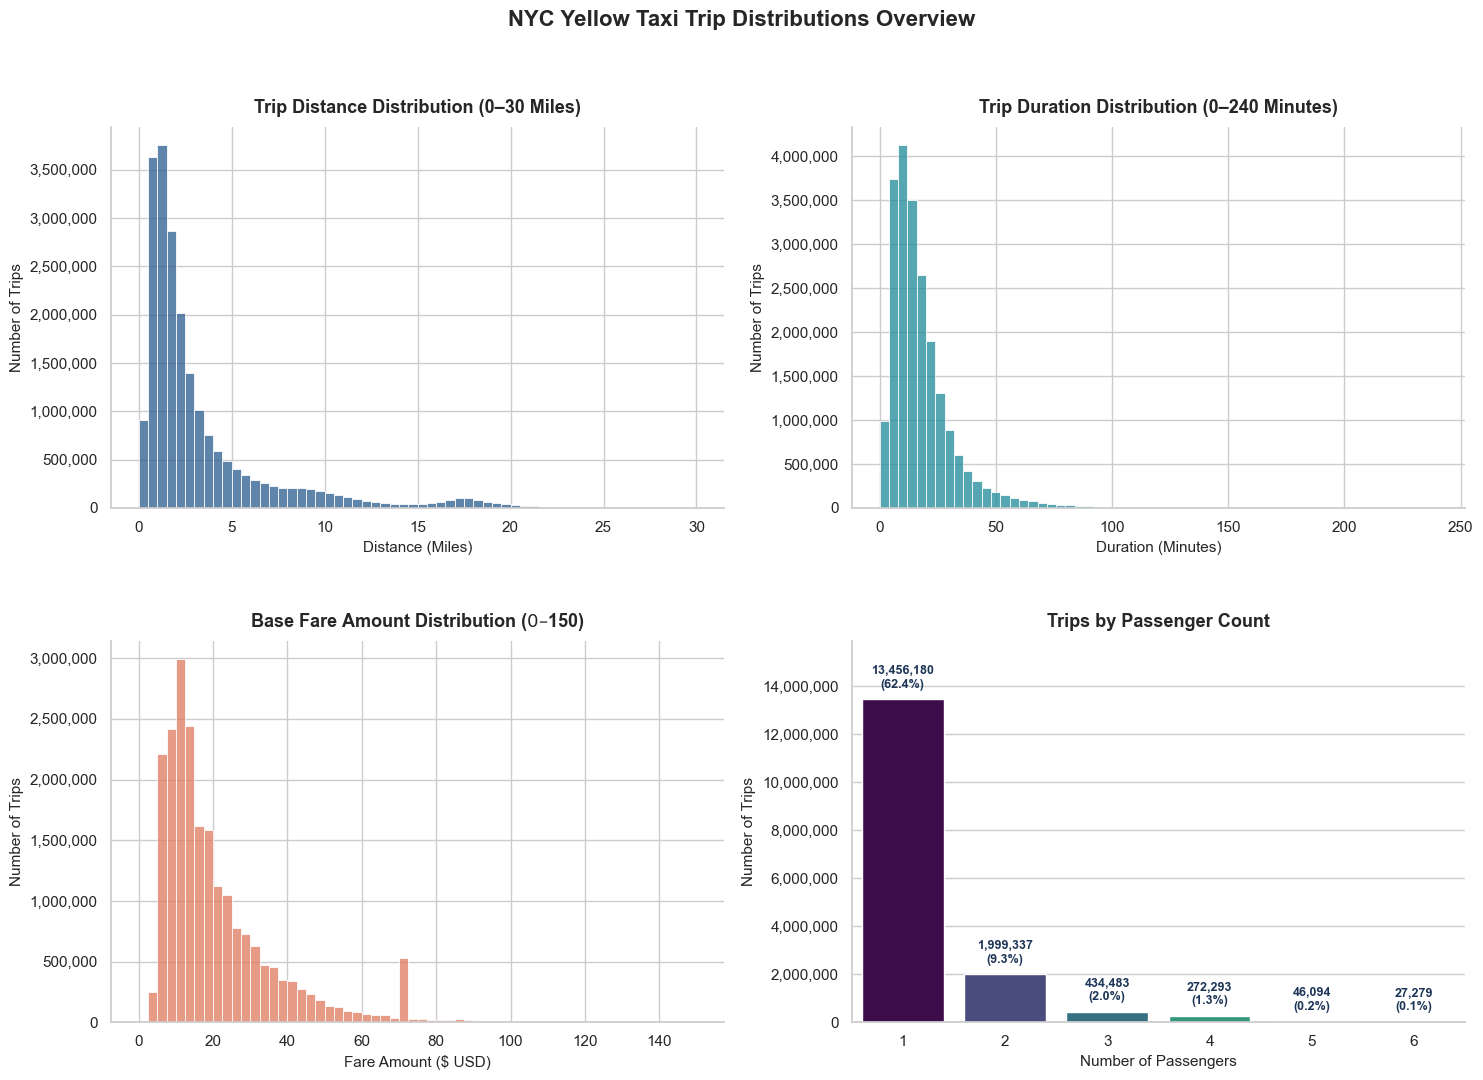

In [23]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("NYC Yellow Taxi Trip Distributions Overview", fontsize=16, fontweight="bold", y=0.98)

# 1. Top-Left: Trip Distance
sns.histplot(df["trip_distance"], bins=60, binrange=(0, 30), color="#2b5c8f", edgecolor="white", ax=axes[0, 0])
axes[0, 0].set_title("Trip Distance Distribution (0–30 Miles)", fontsize=13, fontweight="bold", pad=10)
axes[0, 0].set_xlabel("Distance (Miles)", fontsize=11)
axes[0, 0].set_ylabel("Number of Trips", fontsize=11)

# 2. Top-Right: Trip Duration
sns.histplot(df["trip_duration_min"], bins=60, binrange=(0, 240), color="#1d8a99", edgecolor="white", ax=axes[0, 1])
axes[0, 1].set_title("Trip Duration Distribution (0–240 Minutes)", fontsize=13, fontweight="bold", pad=10)
axes[0, 1].set_xlabel("Duration (Minutes)", fontsize=11)
axes[0, 1].set_ylabel("Number of Trips", fontsize=11)

# 3. Bottom-Left: Fare Amount
sns.histplot(df["fare_amount"],  bins=60, binrange=(0, 150), color="#e07a5f", edgecolor="white", ax=axes[1, 0])
axes[1, 0].set_title("Base Fare Amount Distribution ($0–$150)", fontsize=13, fontweight="bold", pad=10)
axes[1, 0].set_xlabel("Fare Amount ($ USD)", fontsize=11)
axes[1, 0].set_ylabel("Number of Trips", fontsize=11)

# 4. Bottom-Right: Passenger Count
bars1 = sns.countplot(x="passenger_count", data=df, palette="viridis", hue="passenger_count", legend=False, ax=axes[1, 1])

total_trips = len(df)  # Ensure total_trips is defined
# Add data labels (exact count + percentage) above each bar on axes[1, 1]
for bar in bars1.patches:
    height = bar.get_height()
    if height > 0:  # Skip empty bars if any exist
        pct = (height / total_trips) * 100
        axes[1, 1].annotate(
            f"{height:,.0f}\n({pct:.1f}%)",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1d3557")

axes[1, 1].set_title("Trips by Passenger Count", fontsize=13, fontweight="bold", pad=10)
axes[1, 1].set_xlabel("Number of Passengers", fontsize=11)
axes[1, 1].set_ylabel("Number of Trips", fontsize=11)
axes[1, 1].set_ylim(0, df["passenger_count"].value_counts().max() * 1.18)  # Add headroom for top label

for ax in axes.flat:
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
    sns.despine(ax=ax)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.subplots_adjust(hspace=0.35)
plt.show()

> **Overview**:
> 
> NYC Yellow Taxi activity is overwhelmingly driven by short, single-passenger city trips. Most rides cover under 3 miles, last 10 to 20 minutes, and cost under 20 USD Alongside this core local demand, a distinct secondary segment of long-distance airport transfers creates noticeable secondary peaks around 17–18 miles and 70 USD.
> 
> **Key Findings**:
> - **Trip Distance**: Volume peaks sharply between 1 and 1.5 miles (over 3.7 million trips per bin), with the vast majority of rides finishing under 5 miles. A smaller secondary wave appears between 16 and 20 miles, reflecting long-haul airport routes between Manhattan and JFK.
>
> - **Trip Duration**: Most journeys last between 5 and 20 minutes, peaking at roughly 10 to 12 minutes (~4.1 million trips). Trips longer than 60 minutes are rare, forming a thin tail caused by severe traffic congestion or outer-borough travel.
>
> - **Base Fare Amount**: Fares cluster tightly around 10 USD to 15 USD (~3.0 million trips), aligning with short neighborhood hops. A sharp, isolated spike of over 500,000 trips appears directly at 70 USD, representing the fixed statutory flat rate between JFK Airport and Manhattan.
>
> - **Passenger Count**: Solo riders account for 13,456,180 trips (62.4% of all rides), followed by pairs at 1,999,337 trips (9.3%). Larger groups of 3 to 6 passengers combined make up less than 4% of total volume (434,483 at 3; 272,293 at 4; 46,094 at 5; 27,279 at 6). (The remaining ~25% reflects unrecorded or 0-passenger entries commonly logged by automated taxi meters.) 

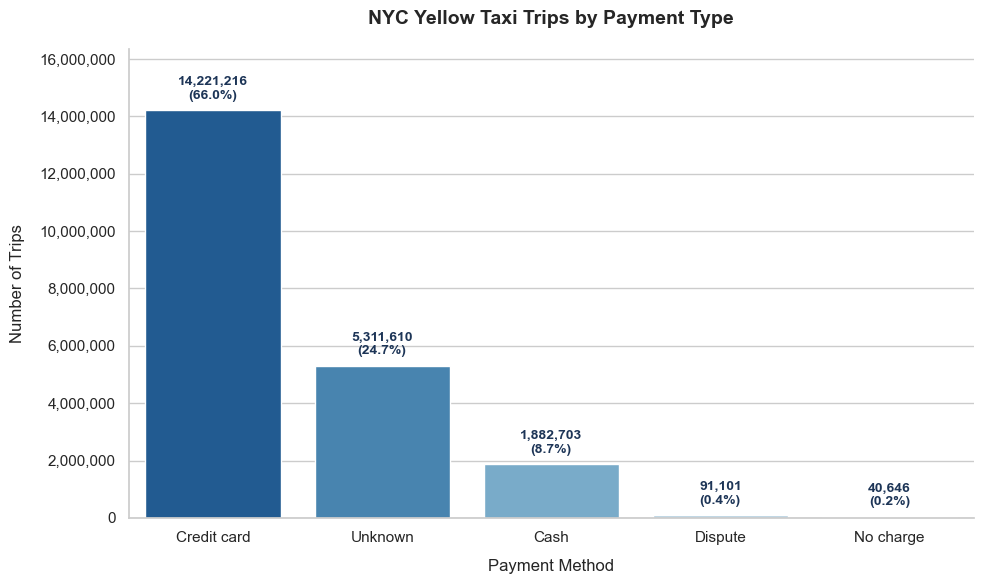

In [24]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Prepare counts and percentages
counts = df["payment_type"].value_counts()
total_trips = len(df)

# Plot vertical bars
bars2 = sns.barplot( x=counts.index, y=counts.values, hue=counts.index, palette="Blues_r", legend=False, ax=ax)

# Add data labels (exact count + percentage) above each bar
for bar in bars2.patches:
    height = bar.get_height()
    pct = (height / total_trips) * 100
    ax.annotate(
        f"{height:,.0f}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),  textcoords="offset points",  ha="center",  va="bottom", fontsize=10, fontweight="bold", color="#1d3557")

# Titles, axis labels, and formatting
ax.set_title("NYC Yellow Taxi Trips by Payment Type", fontsize=14, fontweight="bold", pad=18)
ax.set_xlabel("Payment Method", fontsize=12, labelpad=10)
ax.set_ylabel("Number of Trips", fontsize=12, labelpad=10)

ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0, counts.max() * 1.15)
plt.xticks(fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

> **Overview**:
>
> Digital payments dominate NYC Yellow Taxi transactions, with two-thirds of all trips settled by credit card. Traditional cash fares now make up less than a tenth of recorded rides, while roughly a quarter of records carry an "Unknown" payment designation—a standard artifact of modern third-party app bookings routed through taxi meters.
>
> **Key Findings**:
> 
> - **Credit Card Dominance**: Credit card transactions account for 14,221,216 trips (66.0%), making it the primary payment method across the fleet.
>
> - **Unknown / App-Integrated Trips**: The second-largest category is "Unknown" at 5,311,610 trips (24.7%). In NYC TLC data, this code (0 or NaN) typically represents e-hail and partner app bookings (such as Uber, Curb, or Arro) where payment is processed externally in-app rather than on the cab's physical card terminal.
>
> - **Cash Decline**: Physical cash payments represent only 1,882,703 trips (8.7%).
>
> - **Exceptions & Write-Offs**: Disputed fares (91,101 trips; 0.4%) and no-charge rides (40,646 trips; 0.2%) together represent just 0.6% of total volume, indicating minimal fare friction or voided trips.   


### 6.2 Bivariate/Multivariate Relationships

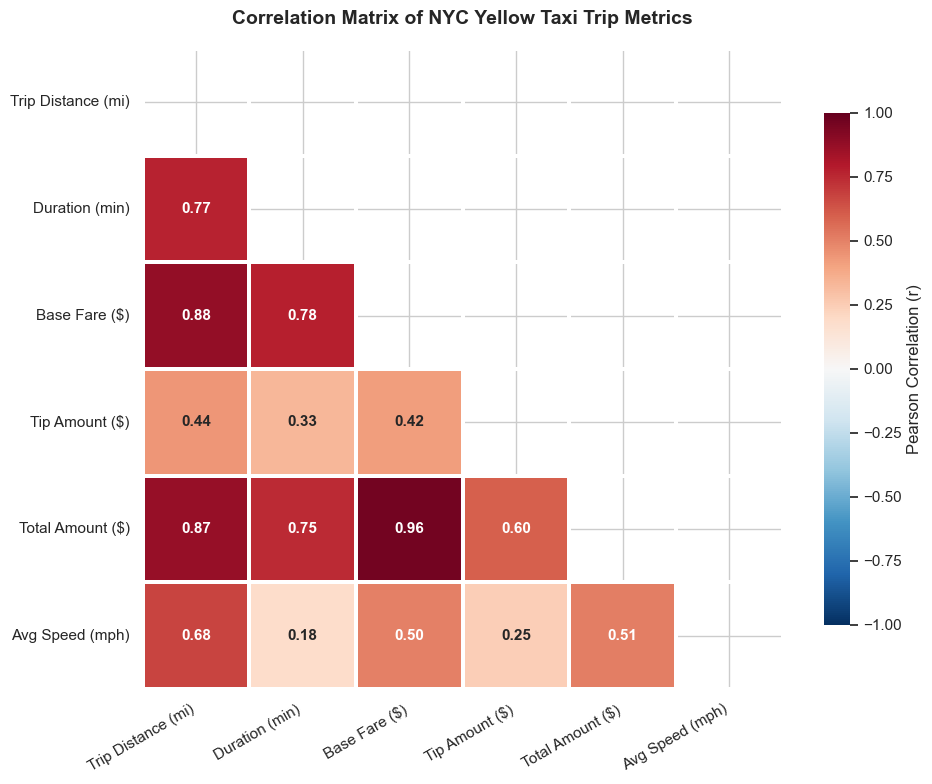

In [25]:
numeric_cols = ["trip_distance", "trip_duration_min", "fare_amount","tip_amount", "total_amount", "avg_speed_mph"]
# Readable display labels for the axes
clean_labels = ["Trip Distance (mi)", "Duration (min)", "Base Fare ($)", "Tip Amount ($)","Total Amount ($)", "Avg Speed (mph)"]

corr = df[numeric_cols].corr()

# Mask the upper triangle to remove duplicate mirror values
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 8))
ax = sns.heatmap( corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, linewidths=1.5, linecolor="white",
                 xticklabels=clean_labels, yticklabels=clean_labels, annot_kws={"size": 11, "weight": "bold"}, 
                 cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"})

plt.title("Correlation Matrix of NYC Yellow Taxi Trip Metrics", fontsize=14, fontweight="bold", pad=18)
plt.xticks(rotation=30, ha="right", fontsize=11)
plt.yticks(rotation=0, fontsize=11)
plt.tight_layout()
plt.show()

> **Overview**:
>
> All core operational metrics across NYC Yellow Taxi trips move in the same positive direction, meaning longer rides consistently produce higher durations, fares, and tips. Pricing is overwhelmingly anchored to trip distance and base meter rates, whereas tip amounts and average vehicle speed show much looser linear relationships due to payment habits and urban traffic dynamics.
> 
> **Key Findings**:
>
> - **Core Fare Drivers**: Base Fare correlates very strongly with Trip Distance (mi) (r = 0.88) and Duration (min) (r = 0.78), confirming that standard metered pricing tracks both mileage and elapsed time. Total Amount aligns nearly one-to-one with Base Fare (r = 0.96). 
>
> - **Distance vs. Time**: Trip Distance (mi) and Duration (min) show a strong positive correlation (r = 0.77), though traffic congestion prevents a perfect linear match.
>
> - **Moderate Tip Scaling**: Tip Amount shows only moderate correlation with Trip Distance (mi) (r = 0.44) and Base Fare (r = 0.42), and a stronger link to Total Amount (r = 0.60). This dampened correlation occurs because cash and unrecorded app trips log 0 tips regardless of how far the passenger traveled.
>
> - **Highway Speed Effect**: Avg Speed (mph) correlates moderately well with Trip Distance (mi) (r = 0.68) and Base Fare (r = 0.50), but very weakly with Duration (min) (r = 0.18). Long-distance rides utilize fast highways and bridges (such as airport corridors), whereas short Manhattan trips spend most of their duration idling in dense street traffic.   

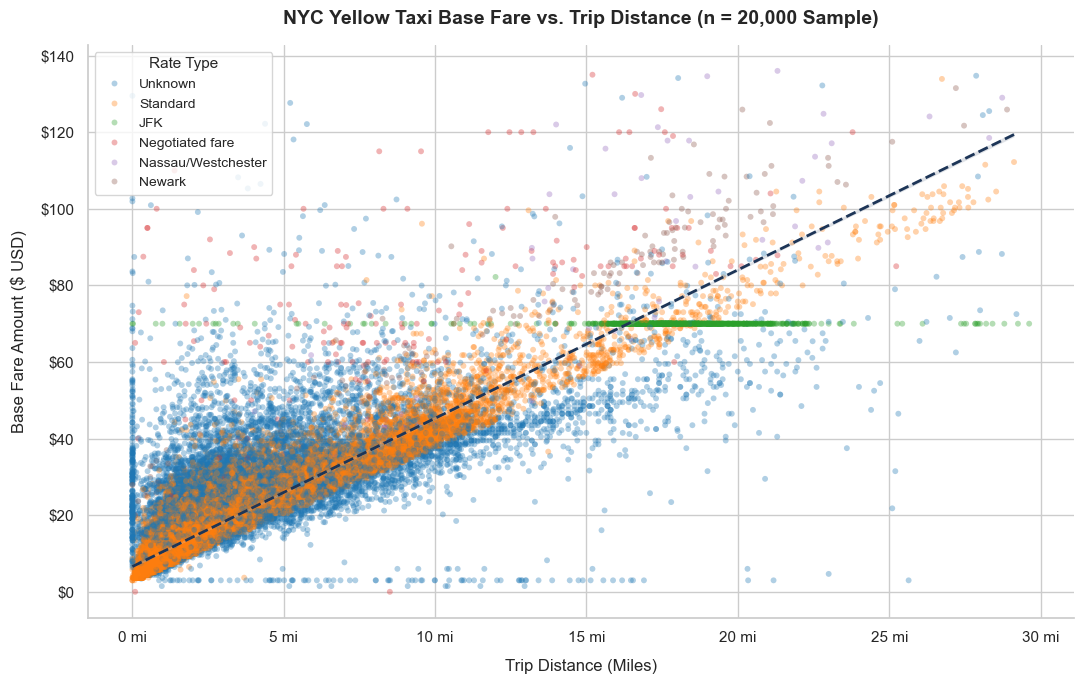

In [26]:
sns.set_theme(style="whitegrid")

# Sample for scatter plots
sample = df.sample(n=min(50_000, len(df)), random_state=RANDOM_STATE)

# Filter out extreme outliers from the visual window
plot_sample = sample[(sample["trip_distance"] <= 40) & (sample["fare_amount"] <= 150)]

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=plot_sample, x="trip_distance", y="fare_amount", hue="RatecodeID", palette="tab10", alpha=0.35, s=18, edgecolor="none", ax=ax)

# Add a linear trendline for standard metered fares to show the baseline rate structure
standard_trips = plot_sample[plot_sample["RatecodeID"] == "Standard"]
sns.regplot(data=standard_trips, x="trip_distance", y="fare_amount", scatter=False, color="#1d3557", 
            line_kws={"linestyle": "--", "linewidth": 2, "label": "Standard Metered Trend"}, ax=ax)

# Format currency on Y-axis and miles on X-axis
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f} mi"))

# Titles, labels, and legend cleanup
ax.set_title("NYC Yellow Taxi Base Fare vs. Trip Distance (n = 20,000 Sample)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Trip Distance (Miles)", fontsize=12, labelpad=10)
ax.set_ylabel("Base Fare Amount ($ USD)", fontsize=12, labelpad=10)
ax.legend(title="Rate Type", frameon=True, facecolor="white", fontsize=10, title_fontsize=11, loc="upper left")

sns.despine()
plt.tight_layout()
plt.show()

> **Overview**:
>
> NYC Yellow Taxi fares follow a predictable upward pricing trend with trip distance, but distinct rate rules carve the market into clear pricing tiers. While standard city rides climb steadily along a diagonal fare line, airport flat rates, suburban surcharges, and app-based pricing create visible horizontal bands and steeper fare trajectories.
>
> **Key Findings**:
>
> - **Standard Metered Trend**: Orange points (Standard rate) form a tight upward diagonal band starting near the initial meter drop (~3 USD–7 USD) and rising linearly with distance. Vertical spread above this lower edge reflects traffic congestion, where idle time adds to the fare without increasing mileage.
>
> - **JFK Flat-Rate Band**: Green points (JFK) form a razor-sharp horizontal line locked at 70 USD, concentrated primarily between 15 and 23 miles. Regardless of traffic or exact route length, Manhattan–JFK trips remain capped at this statutory flat fare.
>
> - **Suburban & Newark Premiums**: Brown (Newark) and purple (Nassau/Westchester) points sit consistently above the standard trendline for trips over 10 miles. These reflect higher out-of-city rate structures and suburban surcharges.
>
> - **Negotiated & Unknown Fares**: Red points (Negotiated fare) scatter widely across horizontal price points (such as 60 USD, 80 USD, 100 USD, 120 USD) independent of distance. Blue points (Unknown, typically e-hail/partner app trips) span both above and below the standard line, reflecting upfront app pricing and promotional or dynamic rate structures.
>
> - **Zero-Distance & Minimum-Fare Artifacts**: A vertical column of points at 0 miles (with fares from 3 USD up to 100+ USD) and a thin horizontal floor around $3 represent canceled rides, stationary wait-time charges, GPS logging dropouts, or flat-rate entries logged before vehicle movement.  

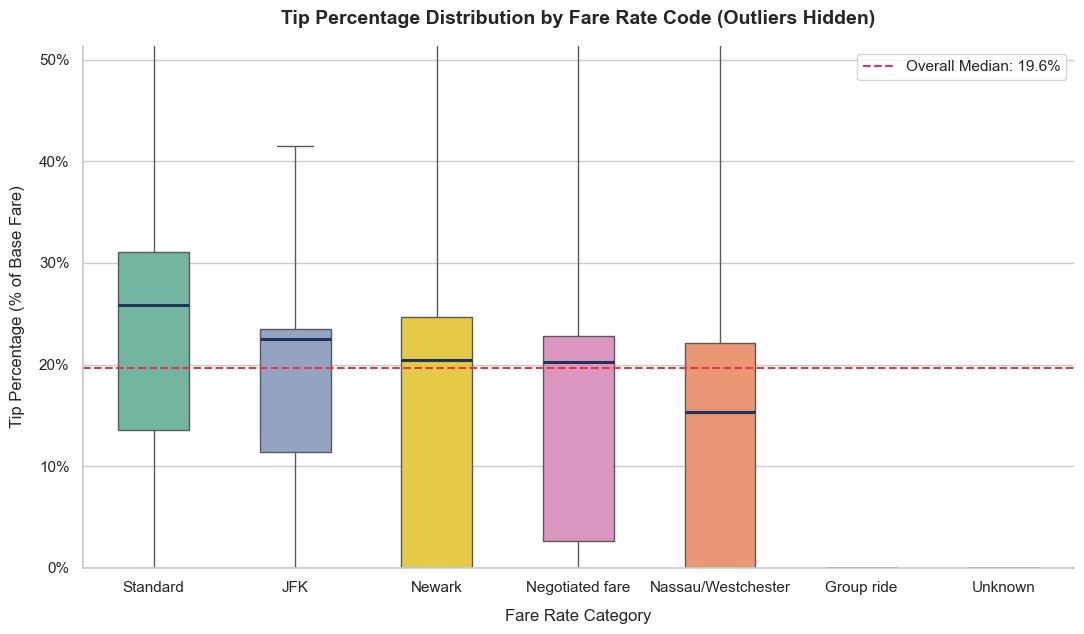

In [27]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 6.5))

# Order categories by median tip % descending
order = (df.groupby("RatecodeID")["tip_pct"].median().sort_values(ascending=False).index)

sns.boxplot(data=df, x="RatecodeID", y="tip_pct", order=order, hue="RatecodeID", palette="Set2", legend=False, width=0.5, showfliers=False,
            medianprops={"color": "#1d3557", "linewidth": 2.2}, ax=ax)

# Add a dashed horizontal line for the overall dataset median tip %
overall_median = df["tip_pct"].median()
ax.axhline(overall_median, color="#e63946", linestyle="--", linewidth=1.5, label=f"Overall Median: {overall_median:.1f}%")

# Format Y-axis as percentages and add headroom
ax.yaxis.set_major_formatter(ticker.PercentFormatter(decimals=0))
ax.set_ylim(0, df.groupby("RatecodeID")["tip_pct"].quantile(0.75).max() * 1.65)

# Titles, axis labels, and legend
ax.set_title("Tip Percentage Distribution by Fare Rate Code (Outliers Hidden)", fontsize=14, fontweight="bold", pad=16)
ax.set_xlabel("Fare Rate Category", fontsize=12, labelpad=10)
ax.set_ylabel("Tip Percentage (% of Base Fare)", fontsize=12, labelpad=10)
ax.legend(frameon=True, facecolor="white", fontsize=11, loc="upper right")

sns.despine()
plt.tight_layout()
plt.show()

> **Overview**:
>
> Tipping behavior across NYC Yellow Taxis is anchored around a 19.6% overall median, but tip generosity varies noticeably depending on the fare structure. Routine city trips earn the highest percentage tips, whereas higher-priced suburban and negotiated fares see lower proportional tipping—and two rate categories record virtually zero recorded tips.
>
> **Key Findings**:
>
> - **Standard Metered Rides Lead in Tip Share**: Standard city fares achieve the highest median tip at roughly 26%, well above the 19.6% dataset benchmark. The middle 50% of trips (interquartile range) falls between roughly 13.5% and 31%, reflecting standard default tip prompts (20%–30%) on in-cab payment screens.
>  
> - **Airport & Negotiated Fares Cluster Near 20%**: JFK flat-rate trips show a median tip of approximately 22.5% with a tight upper quartile around 23.5%, indicating that travelers predominantly select the standard 20% button on the 70 USD flat fare. Newark and Negotiated fare rides both sit right near the overall benchmark at roughly 20%–20.5%, though their boxes stretch all the way down toward 0%–3%, showing a much higher share of zero-tip rides.
> 
> - **Suburban Trips Drop Below Average**: Nassau/Westchester rides fall below the dataset median at roughly 15%, with the lower quartile anchored at 0%. Because out-of-city trips already carry steep metered rates and surcharges, passengers are more likely to tip a flat dollar amount or skip percentage-based tipping.
> 
> - **Zero-Tip Categories (Group ride & Unknown)**: Both Group ride and Unknown appear collapsed flat along the 0% baseline. For Unknown (typically e-hail/partner app bookings), tips are processed externally inside the passenger's mobile app and are not passed back to the taxi meter's tip field.   

### 6.3 Time-of-Day and Seasonality Patterns

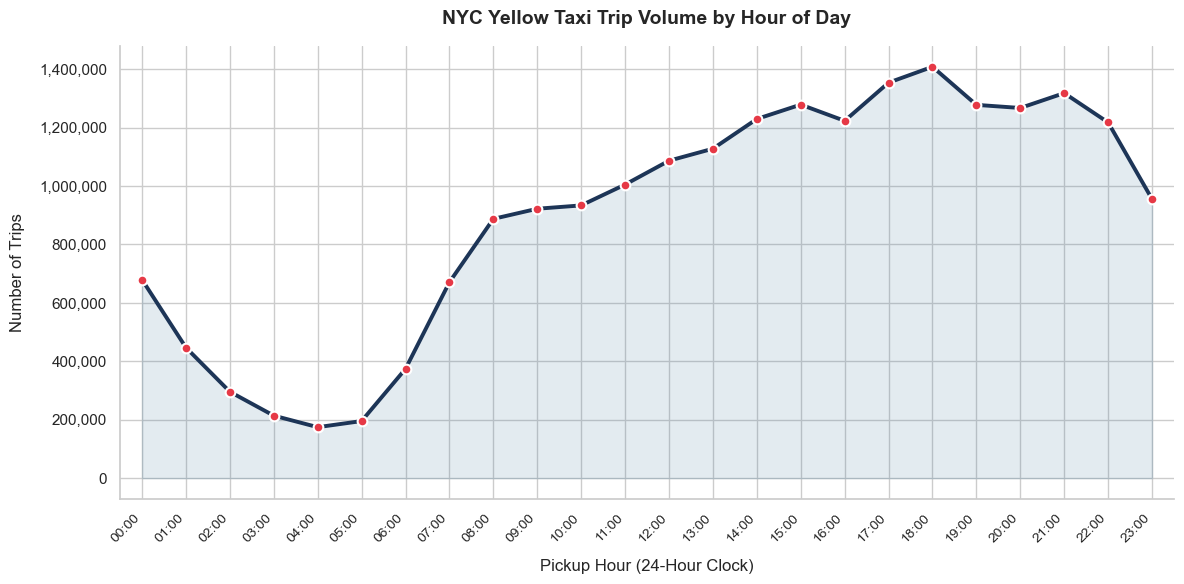

In [28]:
sns.set_theme(style="whitegrid")
hourly = df.groupby("pickup_hour").size().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(  hourly.index, hourly.values, color="#1d3557", linewidth=2.8, marker="o", markersize=7, markerfacecolor="#e63946", markeredgecolor="white",
        markeredgewidth=1.5, zorder=3)
ax.fill_between(hourly.index, hourly.values, color="#457b9d", alpha=0.15, zorder=2)

# Format X-axis as readable 24-hour clock labels (00:00 to 23:00)
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=45, ha="right", fontsize=10)
ax.set_xlim(-0.5, 23.5)

# Format Y-axis with thousand separators
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

# Titles and axis labels
ax.set_title("NYC Yellow Taxi Trip Volume by Hour of Day", fontsize=14, fontweight="bold", pad=16)
ax.set_xlabel("Pickup Hour (24-Hour Clock)", fontsize=12, labelpad=10)
ax.set_ylabel("Number of Trips", fontsize=12, labelpad=10)

sns.despine()
plt.tight_layout()
plt.show()

> **Overview**:
>
> NYC Yellow Taxi demand follows a pronounced 24-hour urban rhythm, surging from an early-morning lull into a sustained afternoon and evening rush. Unlike traditional commuter transit that peaks sharply twice a day and drops off midday, taxi usage builds steadily throughout business hours and remains elevated well into the night.
>
> **Key Findings**:
>
> - **Overnight Trough (04:00)**: Trip volume drops steadily after midnight (680,000 trips at 00:00) to its lowest point of the day at 04:00 (under 200,000 trips), marking the quietest window for fleet activity and ideal timing for shift changes or vehicle maintenance.
>
> - **Rapid Morning Climb (05:00 – 08:00)**: Demand accelerates sharply starting at 06:00 (375,000 trips) and more than doubles by 08:00 (890,000 trips) as morning commuters and early airport travelers hit the streets.
>
> - **Steady Midday Growth (09:00 – 15:00)**: Rather than dipping after morning rush hour, ride volume climbs continuously through late morning and lunch—crossing 1,000,000 trips per hour by 11:00 and reaching roughly 1,280,000 trips at 15:00.
>
> - **Afternoon Shift-Change Dip (16:00)**: A brief, noticeable pullback occurs at 16:00 (~1,220,000 trips). In NYC Yellow Taxi operations, this corresponds directly to the traditional 4:00 PM – 5:00 PM driver shift change, when active cabs temporarily leave central Manhattan to swap drivers at fleet garages.
>
> - **Evening Rush Peak (18:00)**: Demand rebounds immediately to hit its single highest daily peak at 18:00 (6:00 PM) with just over 1,400,000 trips, driven by overlapping office departures, dinner plans, and evening entertainment.
>
> - **Sustained Nightlife Plateau (19:00 – 22:00)**: Evening volume stays consistently high above 1.2 million trips per hour through 22:00, including a secondary nightlife bump at 21:00 (~1,320,000 trips) before tapering off toward midnight.   
>

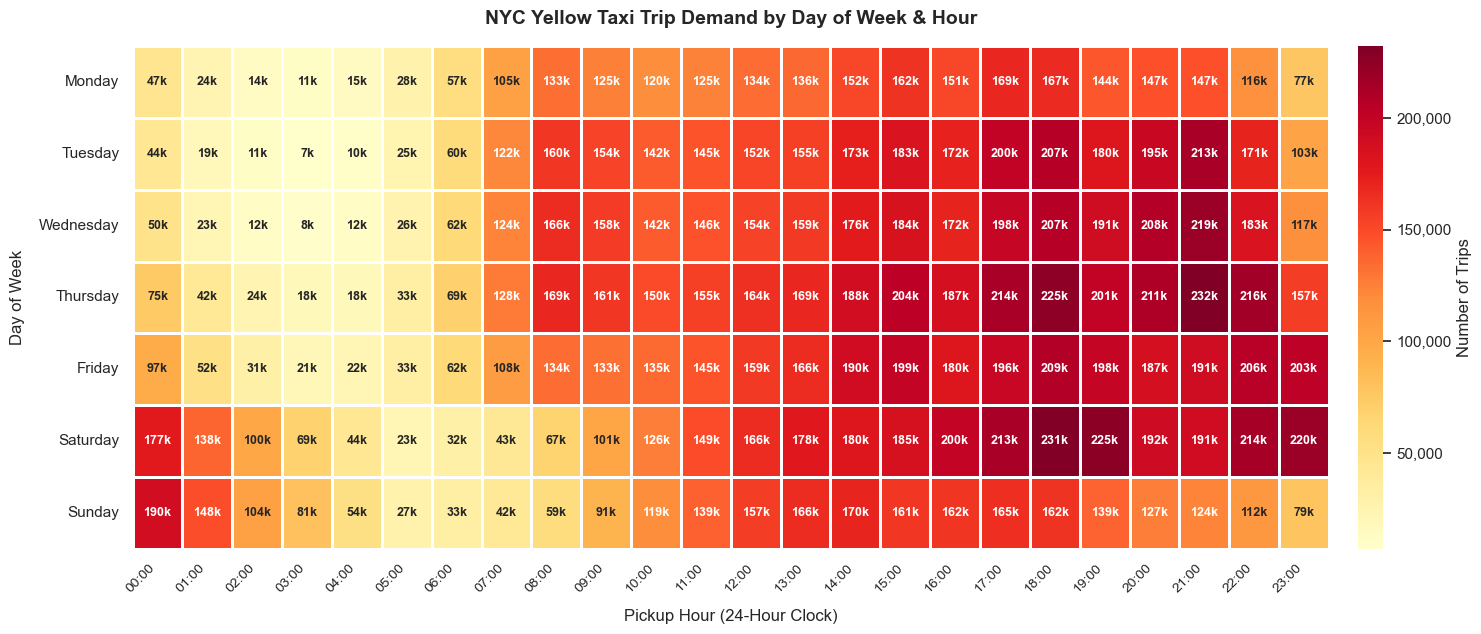

In [29]:
sns.set_theme(style="white")
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Aggregate trip counts by day of week and hour
heatmap_data = (df.groupby(["pickup_dow", "pickup_hour"]) .size() .unstack(fill_value=0)
                .reindex(index=dow_order, columns=range(24), fill_value=0))

# Convert raw counts to thousands (K) for clean, readable cell annotations
annot_matrix = heatmap_data.map(lambda x: f"{x / 1000:.0f}k" if x >= 1000 else f"{x}")

plt.figure(figsize=(16, 6.5))
ax = sns.heatmap( heatmap_data, annot=annot_matrix, fmt="", cmap="YlOrRd", linewidths=1,  linecolor="white", annot_kws={"size": 9, "weight": "bold"},
                 cbar_kws={"label": "Number of Trips", "pad": 0.02})

# Format colorbar ticks with thousand separators
colorbar = ax.collections[0].colorbar
colorbar.ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

# Format X-axis as 24-hour clock labels (00:00 to 23:00) and keep Y-axis horizontal
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=45, ha="right", fontsize=10)
ax.set_yticklabels(dow_order, rotation=0, fontsize=11)

# Titles and axis labels
plt.title("NYC Yellow Taxi Trip Demand by Day of Week & Hour", fontsize=14, fontweight="bold", pad=16)
plt.xlabel("Pickup Hour (24-Hour Clock)", fontsize=12, labelpad=10)
plt.ylabel("Day of Week", fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

> **Overview**:
>
> NYC Yellow Taxi demand follows two distinct weekly rhythms: a structured weekday commuter schedule from Monday through Friday and a late-night leisure surge across Friday night, Saturday, and early Sunday morning. Mid-week evenings (especially Thursday) generate the highest overall trip volumes, whereas weekday pre-dawn hours mark the quietest periods of the week.
>
> **Key Findings**:
>
> - **Mid-Week Peak Demand**: Thursday is the busiest overall day, peaking at 232k trips at 21:00 alongside sustained volume from 17:00 to 22:00 (214k to 232k trips per hour). Wednesday (219k at 21:00) and Tuesday (213k at 21:00) follow a nearly identical evening surge.
> 
> - **Weekday Commuter & Shift-Change Pattern**: Monday through Friday show a sharp morning ramp starting at 07:00–08:00 (105k–169k trips). Every weekday exhibits a brief, consistent dip at 16:00 (151k on Monday down to 180k on Friday) caused by the 4:00 PM driver shift handoff, immediately followed by evening rush peaks between 17:00 and 21:00.
>
> - **Weekend Nightlife Inversion**: Unlike Monday–Thursday, where midnight (00:00) demand drops to 44k–75k trips, Saturday (177k at 00:00; 138k at 01:00) and Sunday (190k at 00:00; 148k at 01:00) surge heavily during late-night and early-morning hours as Friday and Saturday nightlife crowds head home. Friday night (206k at 22:00; 203k at 23:00) and Saturday night (214k at 22:00; 220k at 23:00) maintain over 200,000 rides per hour right up to midnight.
>
> - **Slower Weekend Mornings & Early Sunday Wind-Down**: Weekend mornings start much later than weekdays—Saturday and Sunday stay below 70k trips per hour until 09:00 (101k Saturday, 91k Sunday), compared to 125k–161k on weekdays. Sunday evening tapers off noticeably earlier than any other day, dropping from 165k at 17:00 down to 79k by 23:00 ahead of the Monday workweek.
>
> - **Weekly Trough**: The lowest demand across the entire week occurs on Tuesday at 03:00 (7k trips) and Wednesday at 03:00 (8k trips).   

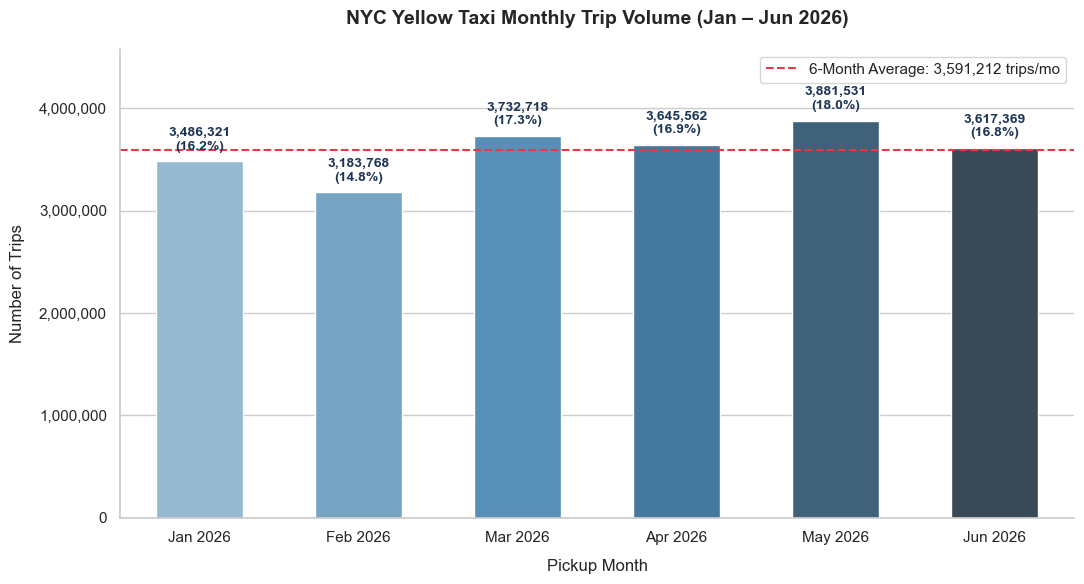

In [30]:
sns.set_theme(style="whitegrid")

# Define the exact 2026 H1 month sequence
months_2026 = ["2026-01", "2026-02", "2026-03", "2026-04", "2026-05", "2026-06"]

# Filter to 2026-01 through 2026-06
df_h1 = df[df["pickup_month"].astype(str).isin(months_2026)]
monthly = (df_h1.groupby("pickup_month").size().reindex(months_2026, fill_value=0))

month_labels = [pd.to_datetime(m).strftime("%b %Y") for m in months_2026]
total_trips = monthly.sum()

fig, ax = plt.subplots(figsize=(11, 6))
# Plot vertical bars with a clean blue palette
bars = sns.barplot( x=month_labels, y=monthly.values, hue=month_labels, palette="Blues_d", legend=False, width=0.55, ax=ax)

# Annotate exact trip count and percentage share above each bar
for bar in bars.patches:
    height = bar.get_height()
    pct = (height / total_trips) * 100 if total_trips > 0 else 0
    ax.annotate(f"{height:,.0f}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, height), xytext=(0, 6),
                    textcoords="offset points", ha="center", va="bottom", fontsize=10, fontweight="bold", color="#1d3557")

# Add a dashed horizontal line for the 6-month average
avg_trips = monthly.mean()
ax.axhline(avg_trips, color="#e63946", linestyle="--", linewidth=1.5, label=f"6-Month Average: {avg_trips:,.0f} trips/mo")

# Titles, axis labels, and formatting
ax.set_title("NYC Yellow Taxi Monthly Trip Volume (Jan – Jun 2026)", fontsize=14, fontweight="bold", pad=18)
ax.set_xlabel("Pickup Month", fontsize=12, labelpad=10)
ax.set_ylabel("Number of Trips", fontsize=12, labelpad=10)

ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0, monthly.max() * 1.18)
ax.legend(frameon=True, facecolor="white", fontsize=11, loc="upper right")

sns.despine()
plt.tight_layout()
plt.show()

> **Overview**:
>
> NYC Yellow Taxi demand across the first half of 2026 totals roughly 21.55 million trips, averaging 3,591,212 trips per month. Monthly volume follows a clear seasonal progression: ridership dips during the winter trough in February before climbing into a sustained spring peak from March through May.
>
> **Key Findings**:
>
> - **Winter Trough (Feb 2026)**: February records the lowest monthly volume at 3,183,768 trips (14.8%), sitting roughly 11.3% below the 6-month average. This drop reflects both post-holiday winter travel slowdowns and February having only 28 calendar days.
>
> - **Sharp Spring Rebound (Mar 2026)**: Trip volume jumps by more than half a million rides (+17.2% month-over-month) in March to 3,732,718 trips (17.3%), crossing well above the 6-month benchmark.
>
> - **H1 Peak (May 2026)**: Demand reaches its 6-month high in May at 3,881,531 trips (18.0%), driven by milder spring weather, peak tourism, and heightened business and event activity across Manhattan.
>
> - **Steady Spring Plateau (Apr & Jun 2026)**: April (3,645,562 trips; 16.9%) and June (3,617,369 trips; 16.8%) hold steady just above the 6-month average line. The slight pullback in June reflects early summer departures from the city and June's 30-day calendar length compared to May's 31 days.   


### 6.4 Geospatial/Zone-based Demand

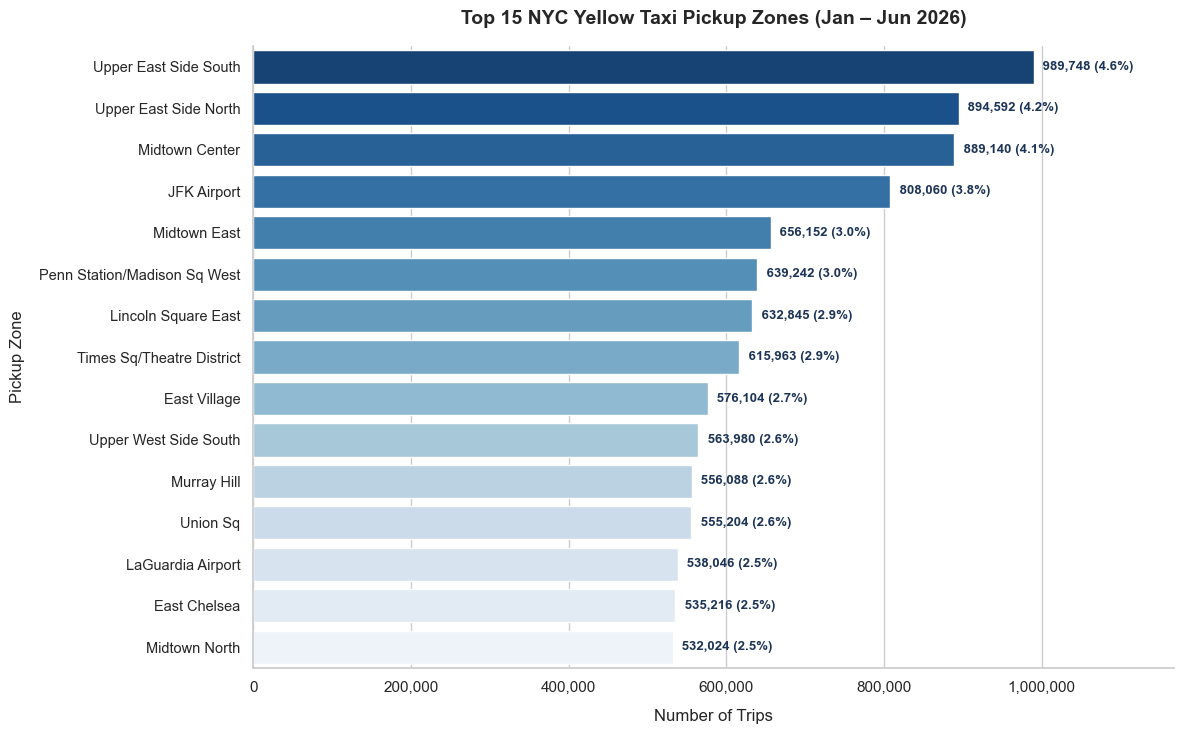

In [31]:
sns.set_theme(style="whitegrid")

# Merge zone lookup table
zones = pd.read_csv(ZONE_LOOKUP_PATH)  
df = df.merge( 
    zones[["LocationID", "Borough", "Zone"]].rename(columns={"LocationID": "PULocationID", "Zone": "pickup_zone", "Borough": "pickup_borough"}),
        on="PULocationID",
        how="left",)

# Prepare Top 15 pickup zones and total trips
top_pickup_zones = df["pickup_zone"].value_counts().head(15)
total_trips = len(df)

fig, ax = plt.subplots(figsize=(12, 7.5))
bars = sns.barplot(x=top_pickup_zones.values, y=top_pickup_zones.index, hue=top_pickup_zones.index, palette="Blues_r", legend=False, ax=ax)

# Add exact trip count and percentage share to the right of each bar
for bar in bars.patches:
    width = bar.get_width()
    pct = (width / total_trips) * 100
    ax.annotate( f" {width:,.0f} ({pct:.1f}%)",  xy=(width, bar.get_y() + bar.get_height() / 2), xytext=(4, 0), textcoords="offset points",
                ha="left", va="center", fontsize=9.5, fontweight="bold", color="#1d3557")

# Titles, axis labels, and formatting
ax.set_title("Top 15 NYC Yellow Taxi Pickup Zones (Jan – Jun 2026)", fontsize=14, fontweight="bold", pad=16)
ax.set_xlabel("Number of Trips", fontsize=12, labelpad=10)
ax.set_ylabel("Pickup Zone", fontsize=12, labelpad=10)

ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, top_pickup_zones.max() * 1.18)
ax.tick_params(axis="y", labelsize=10.5)

sns.despine()
plt.tight_layout()
plt.show()

> **Overview**:
>
> NYC Yellow Taxi pickups are heavily concentrated in Manhattan's commercial core, affluent residential corridors, and major transit hubs, alongside the city's two major airports in Queens. The top 15 pickup zones alone account for roughly 45.5% of all H1 2026 trips (~9.8 million rides out of ~21.55 million total), demonstrating that street-hail taxi demand remains tightly anchored to dense Midtown and Upper East/West Side neighborhoods.
>
> **Key Findings**:
>
> - **Upper East Side Leads All Pickups**: Upper East Side South ranks first with 989,748 trips (4.6%), followed closely by Upper East Side North at 894,592 trips (4.2%). Combined, these two adjacent residential and medical-center zones generate 1.88 million pickups (8.8% of the entire city).
>
> - **Midtown Commercial & Tourist Core**: Midtown Center ranks third (889,140 trips; 4.1%), supported by Midtown East (656,152; 3.0%), Times Sq/Theatre District (615,963; 2.9%), and Midtown North (532,024; 2.5%). Together, these four Midtown zones represent 12.5% of all H1 2026 volume.
>
> - **Major Airport Hubs**: JFK Airport is the #4 overall pickup location with 808,060 trips (3.8%), while LaGuardia Airport ranks 13th with 538,046 trips (2.5%). Combined, airport taxi stands account for 1.35 million trips (6.3%) of total demand.
>
> - **Transit & Downtown Activity Centers**: Penn Station/Madison Sq West (639,242 trips; 3.0%) highlights strong intercity commuter rail connections, while Lincoln Square East (632,845; 2.9%), East Village (576,104; 2.7%), Upper West Side South (563,980; 2.6%), Murray Hill (556,088; 2.6%), Union Sq (555,204; 2.6%), and East Chelsea (535,216; 2.5%) round out the top 15. 


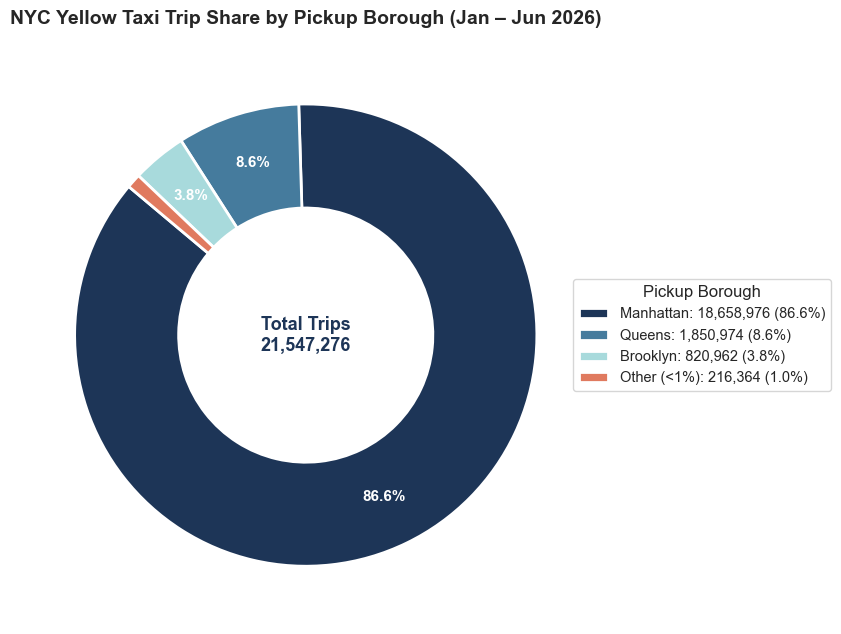

In [32]:
sns.set_theme(style="white")

# Prepare raw counts (fillna("Unknown") ensures missing values are cleanly labeled)
borough_raw = df["pickup_borough"].fillna("Unknown").value_counts()
total_trips = borough_raw.sum()

# Group tiny boroughs
threshold = total_trips * 0.01
major_boroughs = borough_raw[borough_raw >= threshold]
minor_sum = borough_raw[borough_raw < threshold].sum()

if minor_sum > 0:
    plot_counts = pd.concat([major_boroughs, pd.Series({"Other (<1%)": minor_sum})])
else:
    plot_counts = major_boroughs

# Colors matched to your dashboard palette
colors = ["#1d3557", "#457b9d", "#a8dadc", "#e07a5f", "#8d99ae"][:len(plot_counts)]

fig, ax = plt.subplots(figsize=(10, 6.5))
# Plot donut-style pie chart
wedges, texts, autotexts = ax.pie(plot_counts.values, labels=None, autopct=lambda pct: f"{pct:.1f}%" if pct >= 2.0 else "",
                                  pctdistance=0.78, startangle=140, colors=colors, wedgeprops={"width": 0.45, "edgecolor": "white", "linewidth": 2},
textprops={"fontsize": 11, "fontweight": "bold", "color": "white"})

# Add center total callout inside the donut hole
ax.text(0, 0, f"Total Trips\n{total_trips:,.0f}", ha="center", va="center", fontsize=13, fontweight="bold", color="#1d3557")

# Build detailed legend labels with exact counts and 1-decimal percentages
legend_labels = [f"{name}: {count:,.0f} ({count / total_trips * 100:.1f}%)"
                 for name, count in plot_counts.items()]

ax.legend(wedges, legend_labels, title="Pickup Borough", title_fontsize=12, fontsize=10.5, loc="center left",
          bbox_to_anchor=(0.95, 0.5), frameon=True, facecolor="white")

ax.set_title("NYC Yellow Taxi Trip Share by Pickup Borough (Jan – Jun 2026)", fontsize=14, fontweight="bold", pad=16)
plt.tight_layout()
plt.show()

> **Overview**:
>
> Out of 21,547,276 total trips recorded in the first half of 2026, NYC Yellow Taxi operations remain overwhelmingly centralized in Manhattan, which generates nearly nine out of every ten pickups. Outer-borough street-hail volume is comparatively minimal, with Queens serving primarily as an airport gateway rather than a neighborhood cruising market.
>
> **Key Findings**:
>
> - **Manhattan Dominance**: Manhattan accounts for 18,658,976 trips (86.6%), cementing its role as the core revenue and dispatch hub for the Yellow Taxi fleet.
> 
> - **Queens (Airport-Driven Volume)**: Queens ranks second with 1,850,974 trips (8.6%). Comparing this with the zone-level breakdown reveals that JFK Airport (808,060 trips) and LaGuardia Airport (538,046 trips) together generate 1,346,106 rides—meaning roughly 72.7% of all Queens pickups originate directly from airport taxi stands rather than residential streets.
>
> - **Brooklyn & Outer Areas**: Brooklyn captures 820,962 trips (3.8%), reflecting targeted demand in dense hubs like Downtown Brooklyn and Williamsburg. The remaining 216,364 trips (1.0%)—grouped under Other (<1%)—combine the Bronx, Staten Island, Newark Airport (EWR), and unmapped/unknown pickup zones. 


## 7. Save the Cleaned, Analysis-Ready Dataset

In [33]:
output_path = OUTPUT_DIR / "taxi_trips_cleaned.parquet"
df.to_parquet(output_path, index=False, compression="snappy")
print(f"Saved {len(df):,} cleaned rows to {output_path}")
print(f"File size: {output_path.stat().st_size / 1e6:.1f} MB")

Saved 21,547,276 cleaned rows to data\processed\taxi_trips_cleaned.parquet
File size: 699.7 MB


---